# Customer Spending Prediction — Complete Pipeline (EDA → Preprocessing → Modeling → Saved Model)

**Project:** predict `Total_Spent` (sum of the six `Mnt*` columns) for each customer of `marketing_campaign.csv`.
**Stages in this notebook:** EDA (M1+M2) · Preprocessing (M3+M4) · **Modeling, selection and saving (M5+M6)**.
Everything after the saved model (Gradio, FastAPI, Next.js ...) only *loads* the artifact; nothing is retrained there.

## Sections
1. Setup and configuration
2. Load, validate, and define the target
3. Duplicate handling
4. Exploratory data analysis
5. Train/test split and feature engineering (writes `preprocessing.py`)
6. Reusable preprocessing pipeline
7. **Modeling** — baseline, Linear Regression, Random Forest, XGBoost (5-fold CV, raw vs `log1p` target, feature scenarios)
8. **Hyper-parameter tuning**
9. **Final test evaluation and model selection**
10. **Diagnostics** — predicted vs actual, residuals, permutation importance
11. **Save the model and hand off** — `model_pipeline.pkl`, schema, metrics, example predictions, reload test

> **Changes made to the previous team's code (M5+M6):**
> 1. `pre_campaign` scenario still kept derived columns (`Total_Purchases`, `*_Purchase_Share`, `Total_Accepted_Campaigns`) built from the purchase/campaign columns it was meant to drop — fixed.
> 2. Categorical-column detection used `select_dtypes("object")`, which misses the new `str` dtype in pandas 3 — replaced by a dtype-agnostic check.
> 3. The transformers now live in `preprocessing.py` (written by this notebook) so the pickled pipeline can be loaded by Gradio/FastAPI. Classes defined only inside a notebook cannot be unpickled elsewhere.

## 1. Setup and configuration

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys, subprocess, json, joblib, sklearn

from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import TransformedTargetRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
N_JOBS = -1

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.labelsize": 11})

DATA_CANDIDATES = [
    Path("marketing_campaign.csv"),
    Path("data/marketing_campaign.csv"),
    Path("/home/ubuntu/upload/marketing_campaign.csv"),
    Path("/mnt/data/marketing_campaign.csv"),
]
SPEND_COLS = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
PURCHASE_COLS = ["NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
CHANNEL_PURCHASE_COLS = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
CAMPAIGN_COLS = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response"]
# XGBoost is required for the modeling stage; install it automatically if missing.
try:
    import xgboost
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xgboost"])
    import xgboost
from xgboost import XGBRegressor
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| pandas", pd.__version__)


scikit-learn 1.7.2 | xgboost 3.4.1 | pandas 2.3.3


## 2. Load, validate, and define the target

In [3]:
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("marketing_campaign.csv was not found. Update DATA_CANDIDATES at the top of the notebook.")

raw = pd.read_csv(DATA_PATH, sep="\t")
print(f"Loaded: {DATA_PATH}")
print(f"Shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())

Loaded: marketing_campaign.csv
Shape: 2,240 rows × 29 columns


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [4]:
assert set(SPEND_COLS).issubset(raw.columns), "One or more target component columns are missing."
data = raw.copy()
data["Total_Spent"] = data[SPEND_COLS].sum(axis=1)

print("Target summary:")
display(data["Total_Spent"].describe().round(2).to_frame())
print(f"Target skewness: {data['Total_Spent'].skew():.3f}")

Target summary:


,Total_Spent
count,2240.00
mean,605.80
std,602.25
min,5.00
25%,68.75
50%,396.00
75%,1045.50
max,2525.00


Target skewness: 0.861


## 3. Duplicate handling — performed after removing ID and target-component columns

The customer `ID` is an identifier and the six `Mnt*` columns directly define the target. To detect duplicate modeling records rather than duplicate IDs, they are removed before duplicate detection. This is done before the train/test split.

In [5]:
model_base = data.drop(columns=["ID", *SPEND_COLS, "Z_CostContact", "Z_Revenue"], errors="ignore").copy()
duplicates_before = model_base.duplicated().sum()
print("Duplicate modeling rows before removal:", duplicates_before)
model_base = model_base.drop_duplicates().copy()
duplicates_after = model_base.duplicated().sum()
print("Duplicate modeling rows after removal:", duplicates_after)
assert duplicates_after == 0, "Duplicate modeling rows remain after cleaning."

Duplicate modeling rows before removal: 182
Duplicate modeling rows after removal: 0


## 4. Exploratory data analysis

### 4.1 Raw data structure and missingness

,dtype
ID,int64
Year_Birth,int64
Education,object
Marital_Status,object
Income,float64
Kidhome,int64
Teenhome,int64
Dt_Customer,object
Recency,int64
MntWines,int64


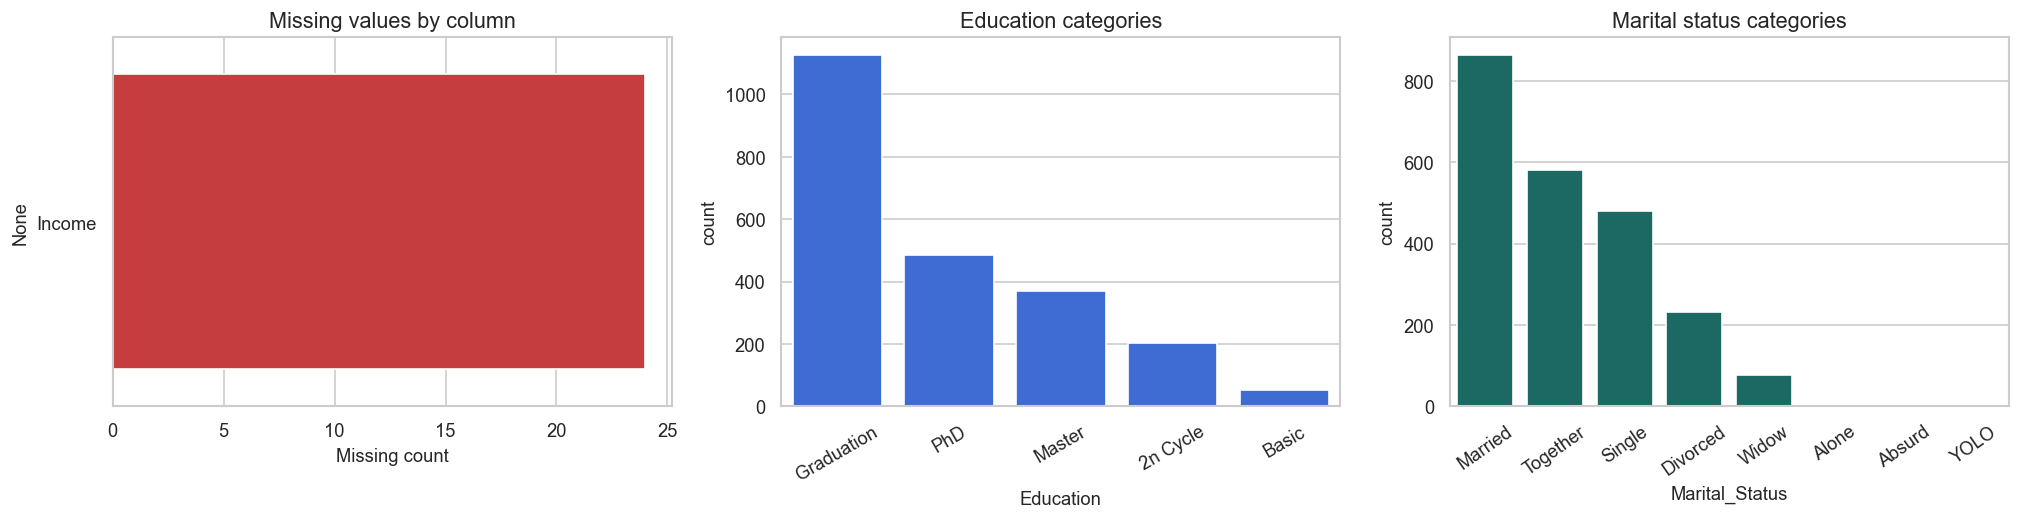

In [6]:
display(raw.dtypes.rename("dtype").to_frame())
missing = raw.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
if len(missing):
    sns.barplot(x=missing.values, y=missing.index, color="#dc2626", ax=axes[0])
    axes[0].set_title("Missing values by column")
    axes[0].set_xlabel("Missing count")
else:
    axes[0].text(.5, .5, "No missing values", ha="center", va="center")
    axes[0].set_axis_off()
sns.countplot(data=raw, x="Education", order=raw["Education"].value_counts().index, color="#2563eb", ax=axes[1])
axes[1].set_title("Education categories")
axes[1].tick_params(axis="x", rotation=30)
sns.countplot(data=raw, x="Marital_Status", order=raw["Marital_Status"].value_counts().index, color="#0f766e", ax=axes[2])
axes[2].set_title("Marital status categories")
axes[2].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

### 4.2 Target and numerical features

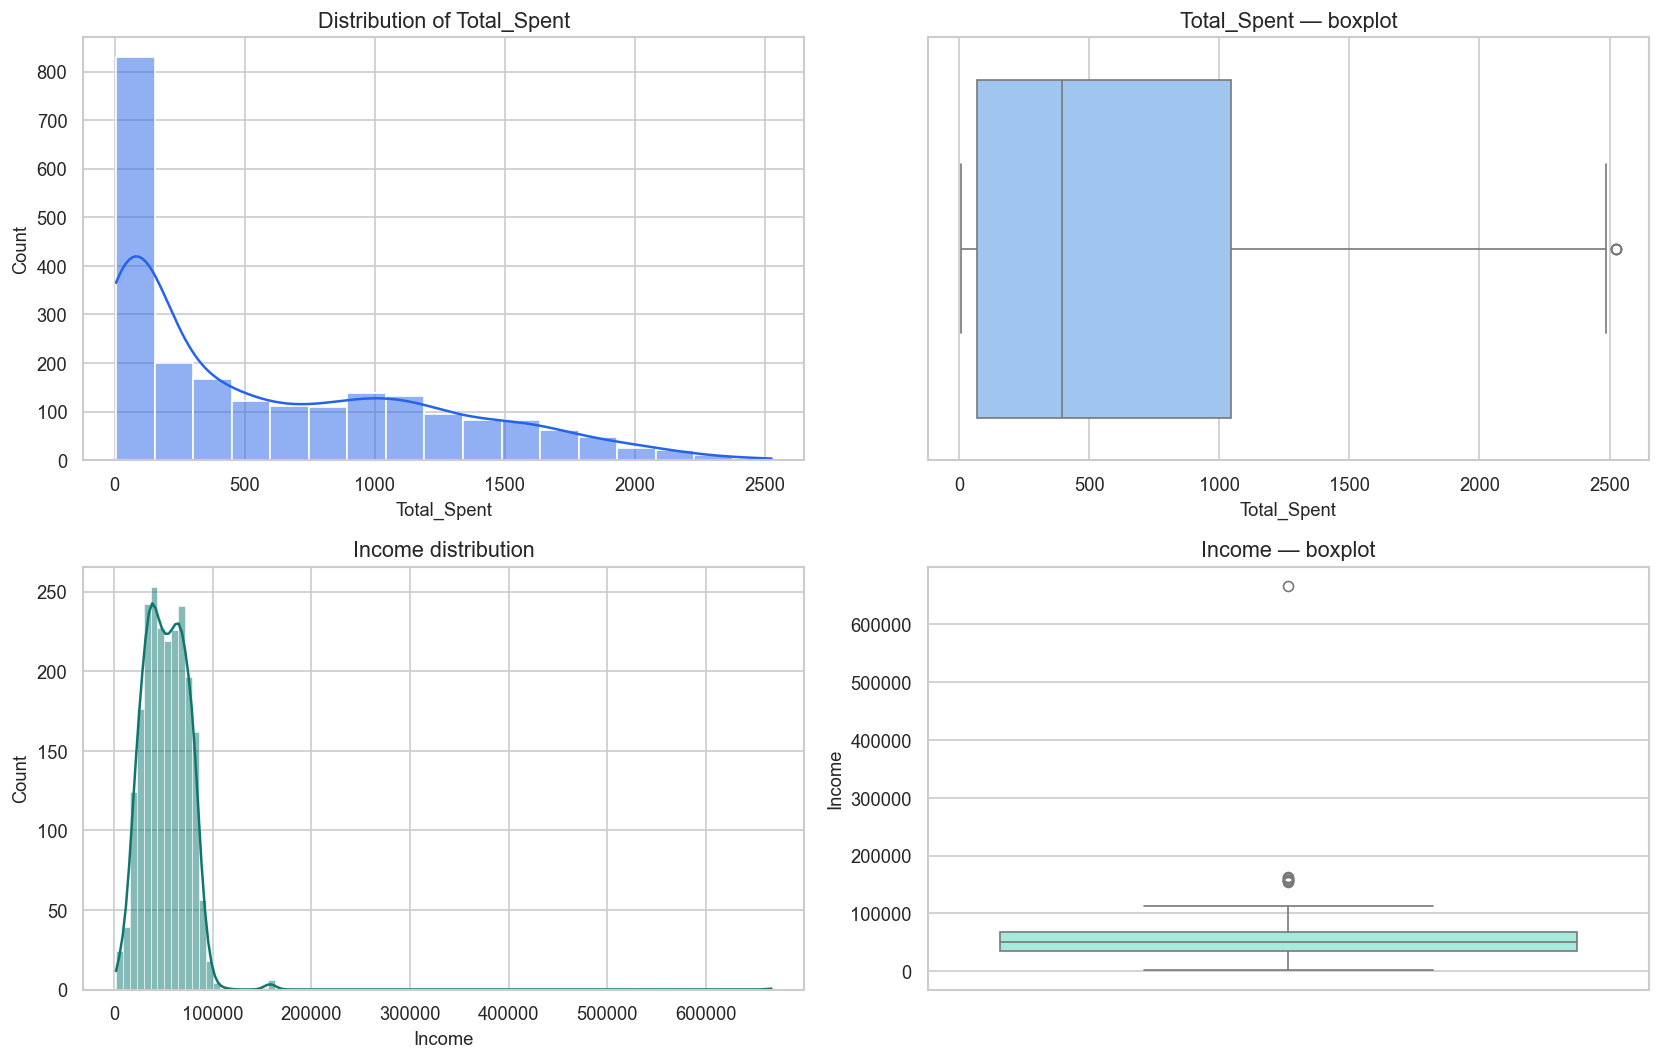

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(data=data, x="Total_Spent", kde=True, color="#2563eb", ax=axes[0,0])
axes[0,0].set_title("Distribution of Total_Spent")
sns.boxplot(data=data, x="Total_Spent", color="#93c5fd", ax=axes[0,1])
axes[0,1].set_title("Total_Spent — boxplot")
sns.histplot(data=raw, x="Income", kde=True, color="#0f766e", ax=axes[1,0])
axes[1,0].set_title("Income distribution")
sns.boxplot(data=raw, y="Income", color="#99f6e4", ax=axes[1,1])
axes[1,1].set_title("Income — boxplot")
plt.tight_layout()
plt.show()

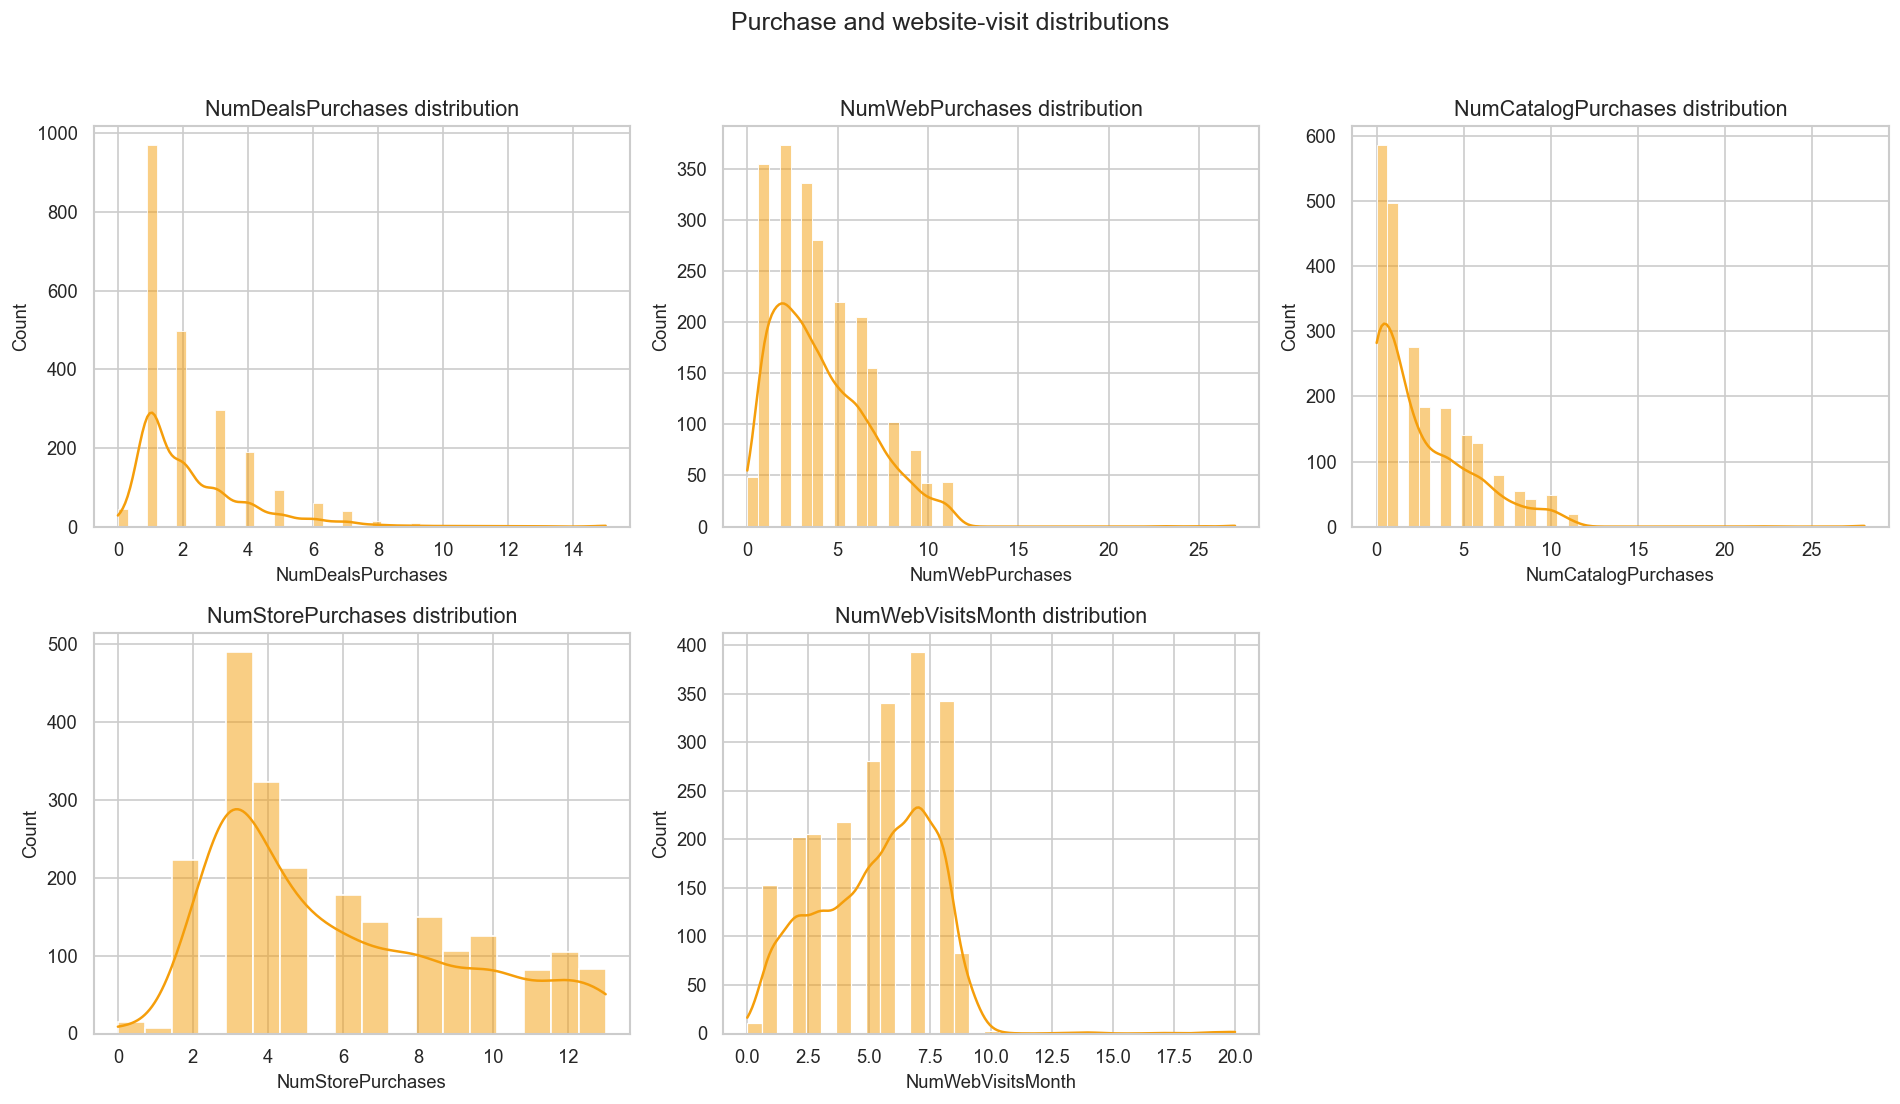

In [8]:
purchase_cols = ["NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, purchase_cols):
    sns.histplot(data=raw, x=col, kde=True, color="#f59e0b", ax=ax)
    ax.set_title(f"{col} distribution")
axes.flat[-1].axis("off")
plt.suptitle("Purchase and website-visit distributions", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

### 4.3 Target relationships

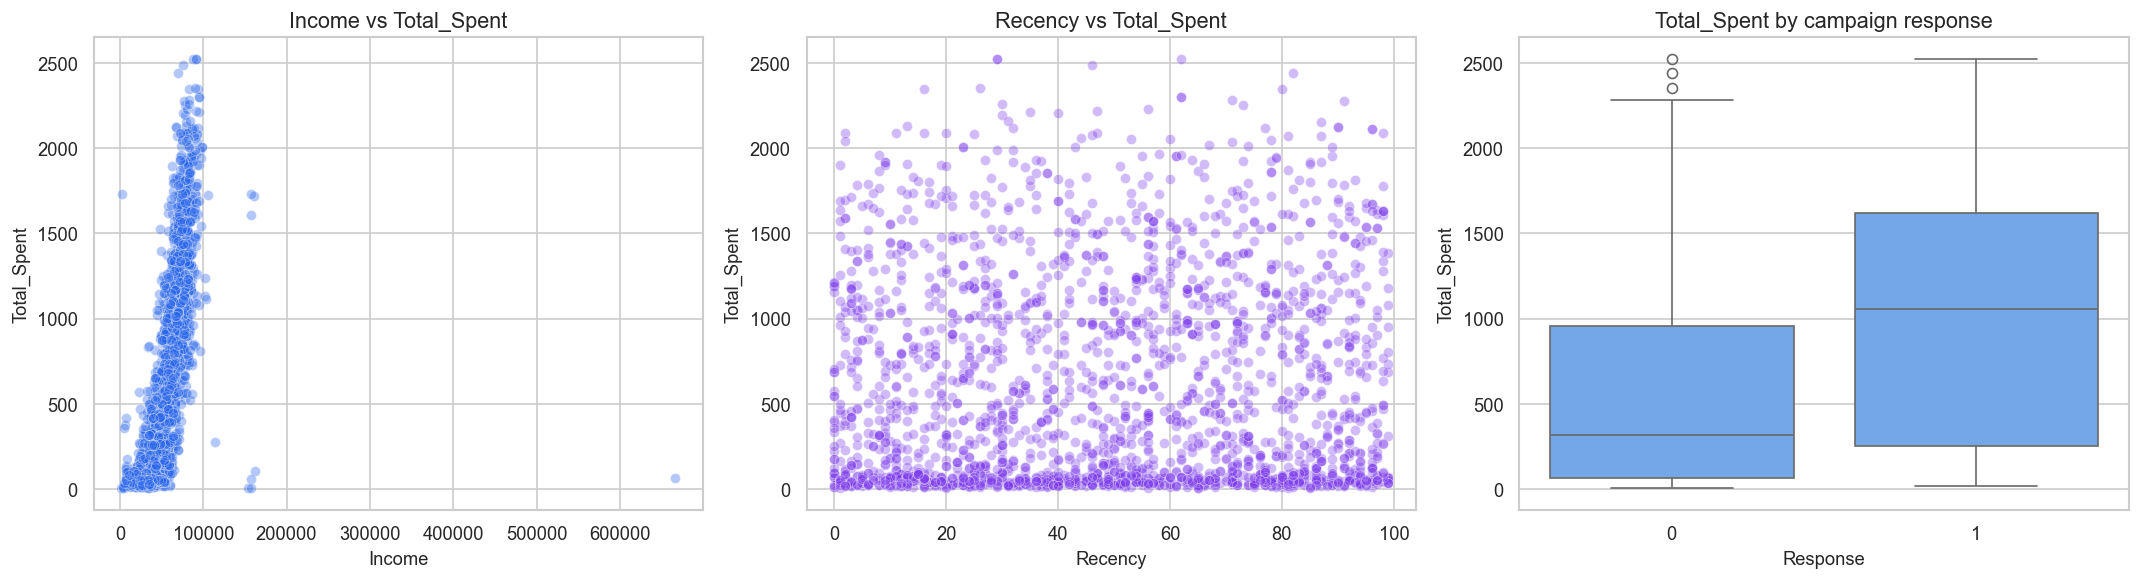

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=data, x="Income", y="Total_Spent", alpha=.35, color="#2563eb", ax=axes[0])
axes[0].set_title("Income vs Total_Spent")
sns.scatterplot(data=data, x="Recency", y="Total_Spent", alpha=.35, color="#7c3aed", ax=axes[1])
axes[1].set_title("Recency vs Total_Spent")
sns.boxplot(data=data, x="Response", y="Total_Spent", color="#60a5fa", ax=axes[2])
axes[2].set_title("Total_Spent by campaign response")
plt.tight_layout()
plt.show()

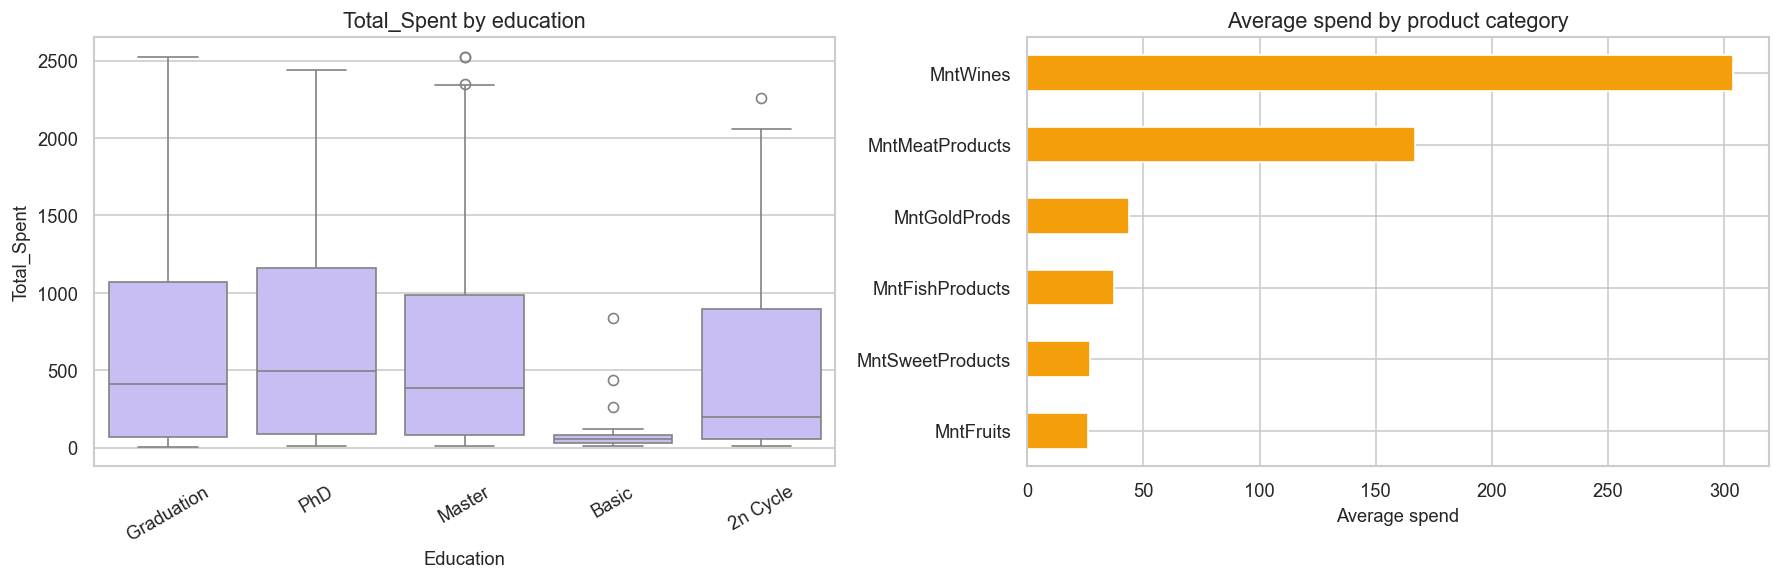

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=data, x="Education", y="Total_Spent", color="#c4b5fd", ax=axes[0])
axes[0].set_title("Total_Spent by education")
axes[0].tick_params(axis="x", rotation=30)
category_means = data[SPEND_COLS].mean().sort_values()
category_means.plot(kind="barh", color="#f59e0b", ax=axes[1])
axes[1].set_title("Average spend by product category")
axes[1].set_xlabel("Average spend")
plt.tight_layout()
plt.show()

### 4.4 Full correlation heatmap

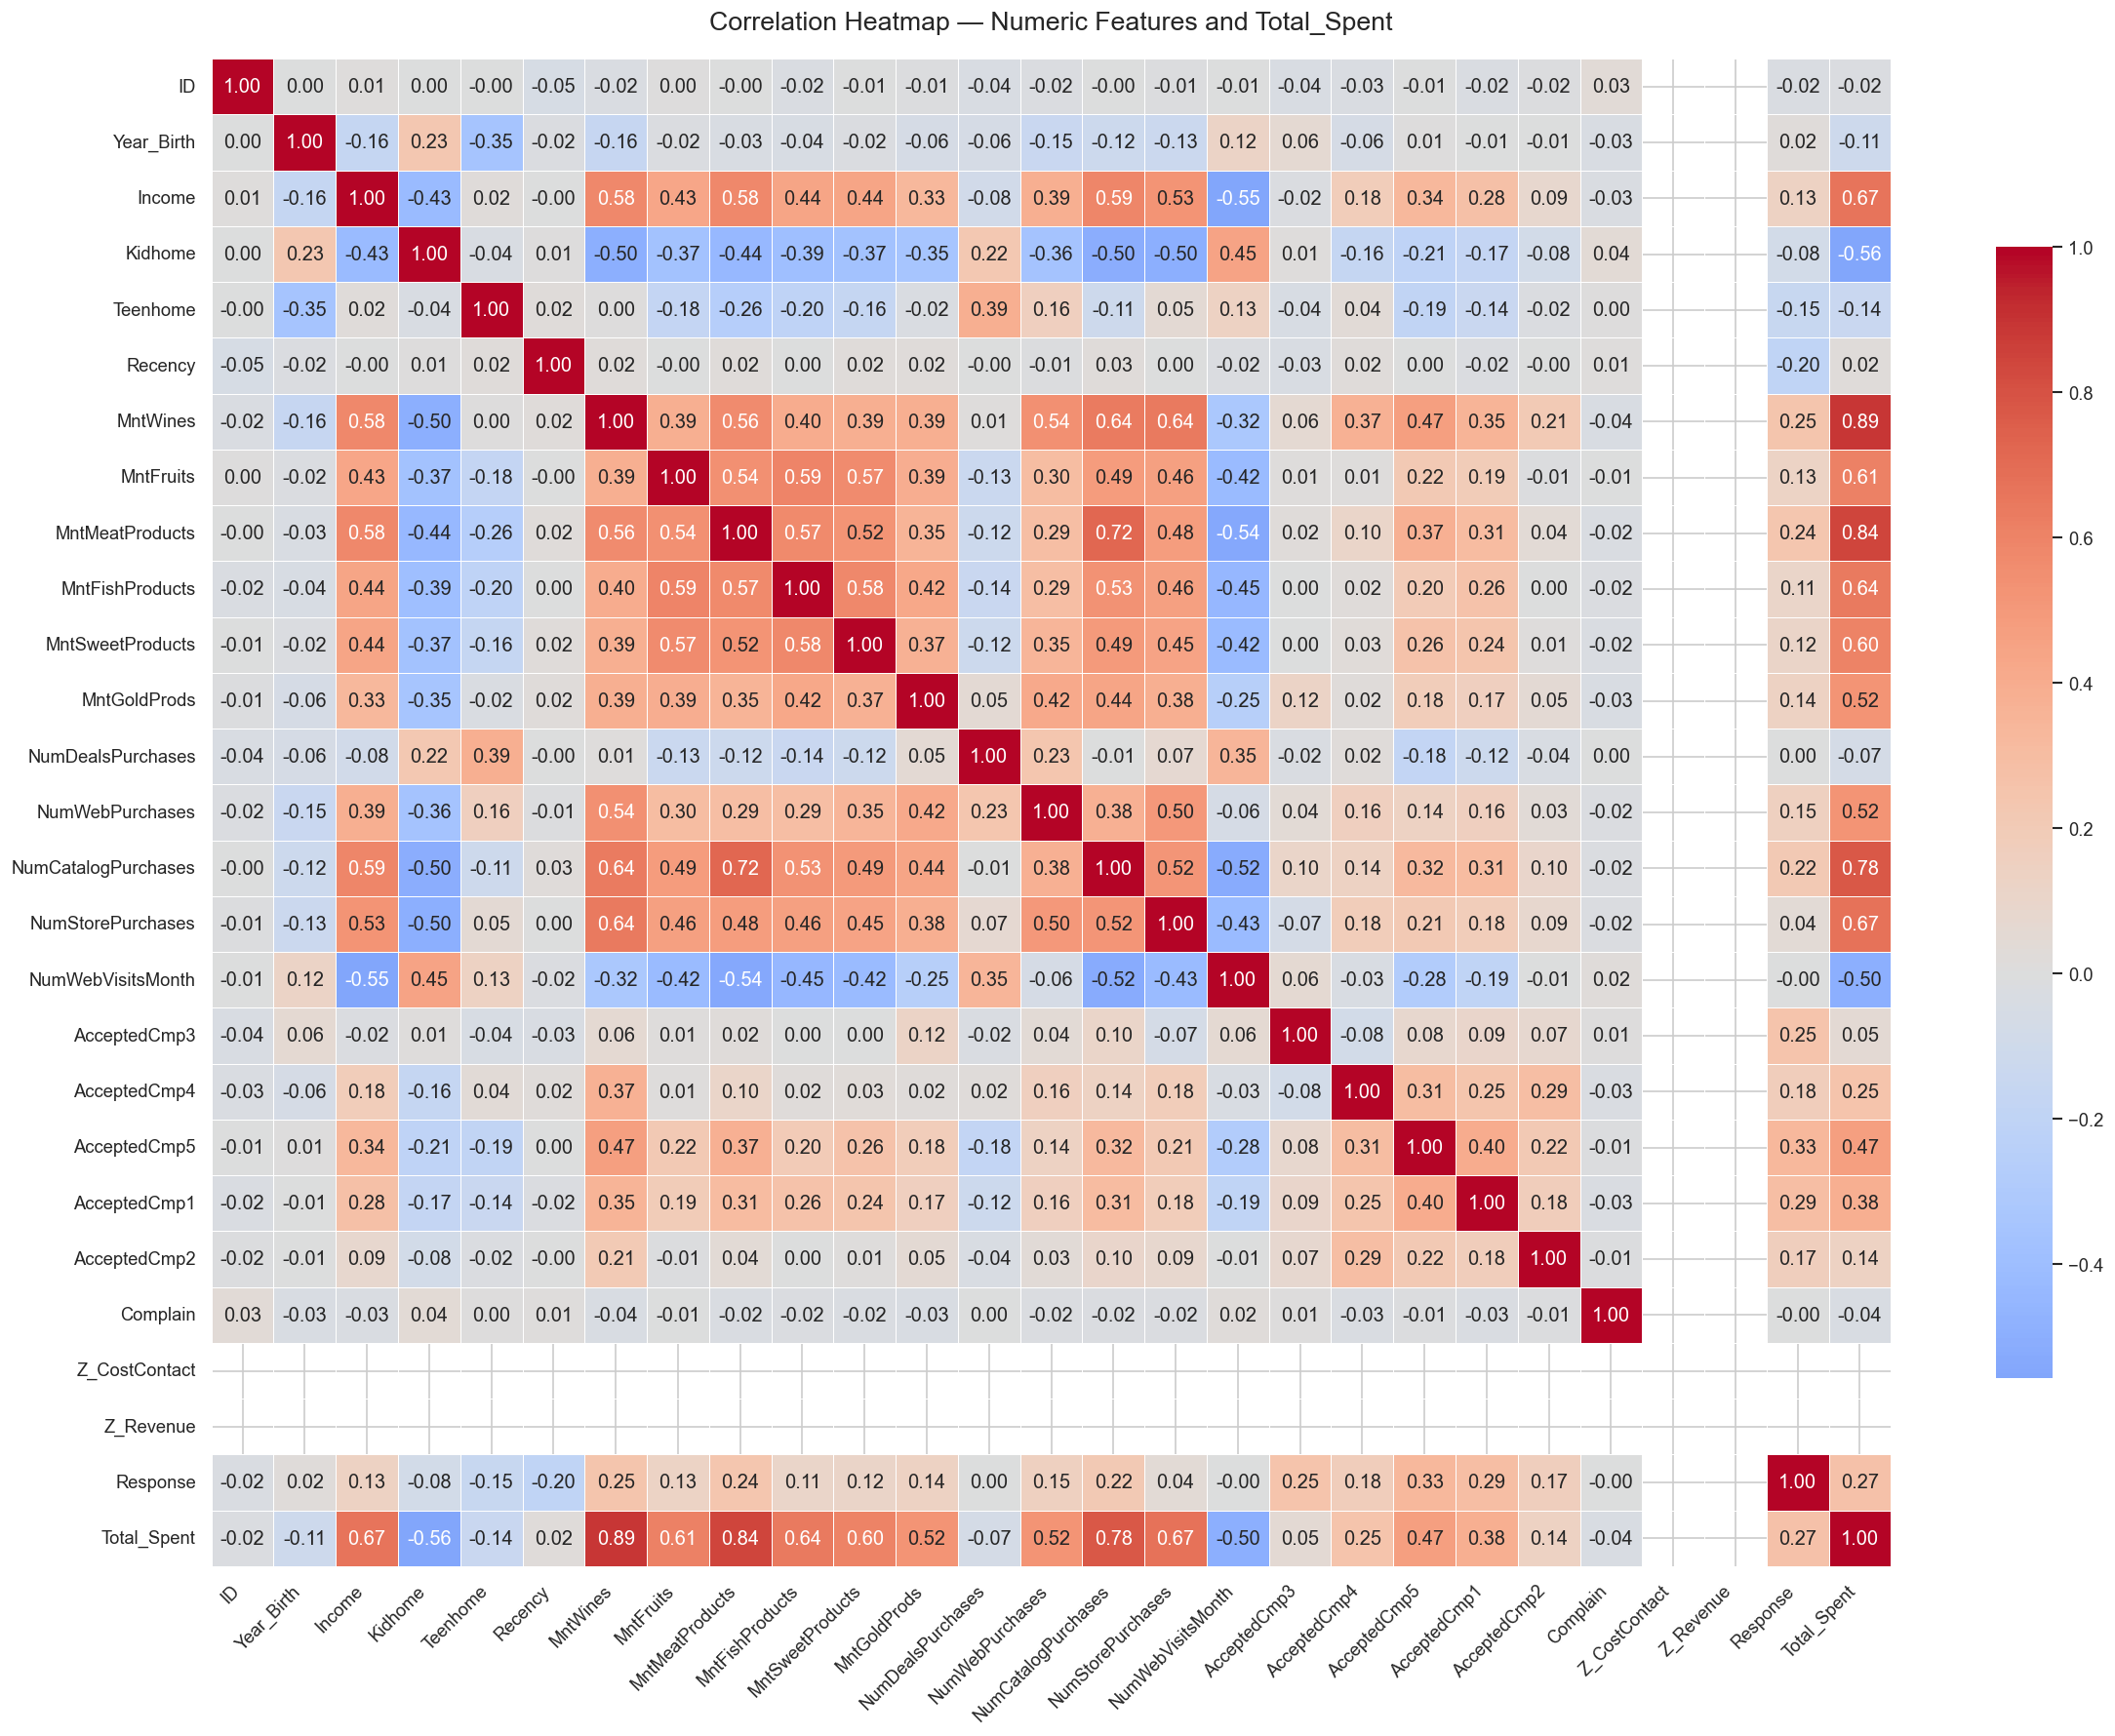

In [11]:
numeric_data = data.select_dtypes(include=np.number)
correlation_matrix = numeric_data.corr()
plt.figure(figsize=(20, 15))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.35, linecolor="white", cbar_kws={"shrink": .75})
plt.title("Correlation Heatmap — Numeric Features and Total_Spent", pad=18, fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Train/test split and train-only feature engineering

Cleaning decisions that do not require statistics—such as mapping invalid labels and setting impossible birth years to missing—are deterministic. Statistics such as the reference date and income clipping limits are learned within the training fold/pipeline.

In [12]:
X_raw = model_base.drop(columns="Total_Spent")
y = model_base["Total_Spent"].copy()
X_train, X_test, y_train, y_test = train_test_split(X_raw, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (1646, 20) Test shape: (412, 20)


### 5.1 Custom feature engineering transformer

In [ ]:
%%writefile preprocessing.py
"""Preprocessing for the Customer Spending project.

Contains the custom transformers and make_pipeline(). The saved model pipeline
references these classes, so this file must be importable (same folder or on
PYTHONPATH) wherever model_pipeline.pkl is loaded (Gradio, FastAPI, ...).
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SPEND_COLS = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
PURCHASE_COLS = ["NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
CHANNEL_PURCHASE_COLS = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
CAMPAIGN_COLS = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response"]


class MarketingFeatureEngineer(BaseEstimator, TransformerMixin):
    """Create features using only the data passed to fit/transform.

    scenario="all"          -> use every non-leaking feature
    scenario="pre_campaign" -> drop everything that is only known after purchases / campaigns,
                               including the features derived from those columns.
    """
    def __init__(self, scenario="all"):
        self.scenario = scenario

    def fit(self, X, y=None):
        dates = pd.to_datetime(X["Dt_Customer"], dayfirst=True, errors="coerce")
        self.reference_date_ = dates.max()
        return self

    def transform(self, X):
        X = X.copy()
        X["Income"] = X["Income"].replace({0: np.nan, 666666: np.nan})
        X.loc[X["Year_Birth"] < 1900, "Year_Birth"] = np.nan
        X["Education"] = X["Education"].replace({"2n Cycle": "Master"})
        X["Marital_Status"] = X["Marital_Status"].replace({
            "Together": "Married", "Absurd": "Single", "YOLO": "Single", "Alone": "Single"
        })

        dt = pd.to_datetime(X["Dt_Customer"], dayfirst=True, errors="coerce")
        X["Customer_Tenure_Days"] = (self.reference_date_ - dt).dt.days
        X["Age"] = self.reference_date_.year - X["Year_Birth"]
        X.loc[~X["Age"].between(18, 100), "Age"] = np.nan

        X["Total_Children"] = X["Kidhome"] + X["Teenhome"]
        X["Has_Children"] = (X["Total_Children"] > 0).astype(int)
        adult_count = X["Marital_Status"].isin(["Married", "Together"]).astype(int) + 1
        X["Household_Size"] = adult_count + X["Total_Children"]
        X["Total_Purchases"] = X[PURCHASE_COLS].sum(axis=1)
        for col in CHANNEL_PURCHASE_COLS:
            short = col.replace("Num", "").replace("Purchases", "")
            X[f"{short}_Purchase_Share"] = X[col] / X["Total_Purchases"].replace(0, np.nan)
        X["Total_Accepted_Campaigns"] = X[[c for c in CAMPAIGN_COLS if c != "Response"]].sum(axis=1)
        X["Income_per_Person"] = X["Income"] / X["Household_Size"].replace(0, np.nan)
        X["Customer_Year"] = dt.dt.year
        X["Customer_Month"] = dt.dt.month

        X = X.drop(columns=["Dt_Customer", "Year_Birth", "Kidhome", "Teenhome"], errors="ignore")
        if self.scenario == "pre_campaign":
            derived = ["Total_Purchases", "Total_Accepted_Campaigns"] + [c for c in X.columns if c.endswith("_Purchase_Share")]
            X = X.drop(columns=[*PURCHASE_COLS, "NumWebVisitsMonth", *CAMPAIGN_COLS, *derived], errors="ignore")
        return X


class IQRClipper(BaseEstimator, TransformerMixin):
    """Clip numeric columns using IQR limits learned on the training data."""
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.q1_ = np.nanpercentile(X, 25, axis=0)
        self.q3_ = np.nanpercentile(X, 75, axis=0)
        iqr = self.q3_ - self.q1_
        self.lower_ = self.q1_ - 1.5 * iqr
        self.upper_ = self.q3_ + 1.5 * iqr
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.clip(X, self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def make_pipeline(X_fit, scenario, model):
    """raw customer columns -> feature engineering -> impute/clip/scale/encode -> model."""
    engineer = MarketingFeatureEngineer(scenario=scenario)
    engineered_train = engineer.fit_transform(X_fit)
    categorical = [c for c in engineered_train.columns if not pd.api.types.is_numeric_dtype(engineered_train[c])]
    numeric = [c for c in engineered_train.columns if c not in categorical]
    binary = [c for c in numeric if set(pd.Series(engineered_train[c].dropna().unique())).issubset({0, 1})]
    continuous = [c for c in numeric if c not in binary]

    try:
        encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse=False)

    continuous_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("iqr_clip", IQRClipper()),
        ("scaler", StandardScaler()),
    ])
    binary_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder),
    ])
    preprocessor = ColumnTransformer([
        ("continuous", continuous_pipe, continuous),
        ("binary", binary_pipe, binary),
        ("categorical", categorical_pipe, categorical),
    ], remainder="drop")
    return Pipeline([
        ("feature_engineering", engineer),
        ("preprocessing", preprocessor),
        ("model", model),
    ])

Overwriting preprocessing.py


### 5.2 Feature availability scenarios

In [14]:
POST_CAMPAIGN_OR_ACTIVITY = [*PURCHASE_COLS, "NumWebVisitsMonth", *CAMPAIGN_COLS]
feature_availability = pd.DataFrame({
    "feature_group": ["Mnt* product spend", "ID", "Purchase counts / website visits", "Campaign acceptance / response", "Demographics and household", "Income and recency"],
    "availability_note": [
        "Target components — always excluded",
        "Identifier — excluded",
        "May be post-activity; excluded in pre_campaign scenario",
        "May be post-campaign; excluded in pre_campaign scenario",
        "Usually available before targeting",
        "Usually available before targeting",
    ],
    "action": ["Leakage: drop", "Drop", "All scenario: keep; pre_campaign: drop", "All scenario: keep; pre_campaign: drop", "Keep", "Keep"],
})
display(feature_availability)

,feature_group,availability_note,action
0,Mnt* product spend,Target components — always excluded,Leakage: drop
1,ID,Identifier — excluded,Drop
2,Purchase counts / website visits,May be post-activity; excluded in pre_campaign...,All scenario: keep; pre_campaign: drop
3,Campaign acceptance / response,May be post-campaign; excluded in pre_campaign...,All scenario: keep; pre_campaign: drop
4,Demographics and household,Usually available before targeting,Keep
5,Income and recency,Usually available before targeting,Keep


## 6. Reusable preprocessing pipeline

The transformers were written to `preprocessing.py` in section 5.1. Importing them from the file (instead of using the notebook copies) guarantees that the pickled pipeline can be loaded by the other teams.

In [15]:
import importlib, preprocessing
importlib.reload(preprocessing)
from preprocessing import MarketingFeatureEngineer, IQRClipper, make_pipeline

# Quick sanity check: preprocessing alone (no model) on the training data.
_probe = make_pipeline(X_train, "all", LinearRegression()).fit(X_train, y_train)
_Z = _probe[:-1].transform(X_train)
print("Raw input columns :", X_train.shape[1])
print("Model input matrix:", _Z.shape, "| NaNs left:", int(np.isnan(_Z).sum()))
display(pd.Series(_probe.named_steps["preprocessing"].get_feature_names_out()).head(12).to_frame("first transformed features"))

Raw input columns : 20
Model input matrix: (1646, 33) | NaNs left: 0


,first transformed features
0,continuous__Income
1,continuous__Recency
2,continuous__NumDealsPurchases
3,continuous__NumWebPurchases
4,continuous__NumCatalogPurchases
5,continuous__NumStorePurchases
6,continuous__NumWebVisitsMonth
7,continuous__Customer_Tenure_Days
8,continuous__Age
9,continuous__Total_Children


## 7. Modeling — compare the candidate algorithms fairly

Rules followed (from the team document):
* Every model uses the **same** train/test split, the **same** 5-fold CV and the **same** preprocessing pipeline.
* The six `Mnt*` columns are never model inputs (target leakage); `ID`, `Z_*` constants are dropped.
* Models: mean **baseline**, **Linear Regression**, **Random Forest**, **XGBoost**.
* Metrics: **MAE** (lower better), **RMSE** (lower better, punishes big errors), **R²** (higher better).
* The **test set is not used for any decision** — tuning and model choice use cross-validation on the training set only.

In [16]:
KF = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

BASE_MODELS = {
    "Baseline (mean)":   lambda: DummyRegressor(strategy="mean"),
    "Linear Regression": lambda: LinearRegression(),
    "Random Forest":     lambda: RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1),
    "XGBoost":           lambda: XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                                              colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=1, tree_method="hist"),
}

def wrap_target(model, log_target):
    """log1p target = train on log(1+spend) and convert predictions back to dollars automatically."""
    if not log_target:
        return model
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1, check_inverse=False)

def cv_eval(name, scenario, log_target, model=None):
    model = model if model is not None else BASE_MODELS[name]()
    pipe = make_pipeline(X_train, scenario, wrap_target(model, log_target))
    res = cross_validate(pipe, X_train, y_train, cv=KF, scoring=SCORING, n_jobs=N_JOBS, error_score="raise")
    return {"model": name, "scenario": scenario, "target": "log1p" if log_target else "raw",
            "CV_MAE": -res["test_MAE"].mean(), "CV_RMSE": -res["test_RMSE"].mean(),
            "CV_RMSE_std": res["test_RMSE"].std(), "CV_R2": res["test_R2"].mean()}

print("Helpers ready. Models:", list(BASE_MODELS))

Helpers ready. Models: ['Baseline (mean)', 'Linear Regression', 'Random Forest', 'XGBoost']


### 7.1 Raw target vs `log1p` target (scenario `all`)
Spending is strongly right-skewed, so we test whether modeling `log1p(Total_Spent)` helps each algorithm.

In [17]:
rows = [cv_eval(n, "all", lt) for n in BASE_MODELS for lt in (False, True)]
cv_target = pd.DataFrame(rows)
display(cv_target.round(3).sort_values(["model", "target"]).reset_index(drop=True))

# best target treatment per model = lowest CV RMSE
best_target = cv_target.loc[cv_target.groupby("model")["CV_RMSE"].idxmin()].set_index("model")["target"].to_dict()
print("Chosen target treatment per model:", best_target)

,model,scenario,target,CV_MAE,CV_RMSE,CV_RMSE_std,CV_R2
0,Baseline (mean),all,log1p,509.398,701.946,23.525,-0.309
1,Baseline (mean),all,raw,527.012,614.621,16.307,-0.003
2,Linear Regression,all,log1p,198.665,684.735,727.415,-1.793
3,Linear Regression,all,raw,173.675,259.363,17.683,0.821
4,Random Forest,all,log1p,125.712,235.921,19.019,0.852
5,Random Forest,all,raw,125.539,227.649,24.475,0.861
6,XGBoost,all,log1p,124.668,233.754,16.793,0.854
7,XGBoost,all,raw,130.239,231.065,24.269,0.857


Chosen target treatment per model: {'Baseline (mean)': 'raw', 'Linear Regression': 'raw', 'Random Forest': 'raw', 'XGBoost': 'raw'}


### 7.2 Which features may the application use? (`all` vs `pre_campaign`)

* **`all`** — demographics, income, recency, purchase counts, website visits and campaign responses. Highest accuracy, but the user must be able to enter purchase/campaign information.
* **`pre_campaign`** — only information known *before* targeting (demographics, income, recency, tenure). Less accurate, but usable for true new-customer prediction.

Both are evaluated so the team can decide which input form to build. **The saved model uses `all`**, the scenario the previous team set up as the default; switching only requires changing `FINAL_SCENARIO` in section 9.

,model,scenario,target,CV_MAE,CV_RMSE,CV_RMSE_std,CV_R2
0,Random Forest,all,raw,125.539,227.649,24.475,0.861
1,XGBoost,all,raw,130.239,231.065,24.269,0.857
2,Linear Regression,all,raw,173.675,259.363,17.683,0.821
3,Baseline (mean),all,raw,527.012,614.621,16.307,-0.003
4,Random Forest,pre_campaign,raw,201.123,295.428,16.633,0.768
5,XGBoost,pre_campaign,raw,201.190,295.738,16.837,0.768
6,Linear Regression,pre_campaign,raw,233.500,320.120,23.840,0.727
7,Baseline (mean),pre_campaign,raw,527.012,614.621,16.307,-0.003


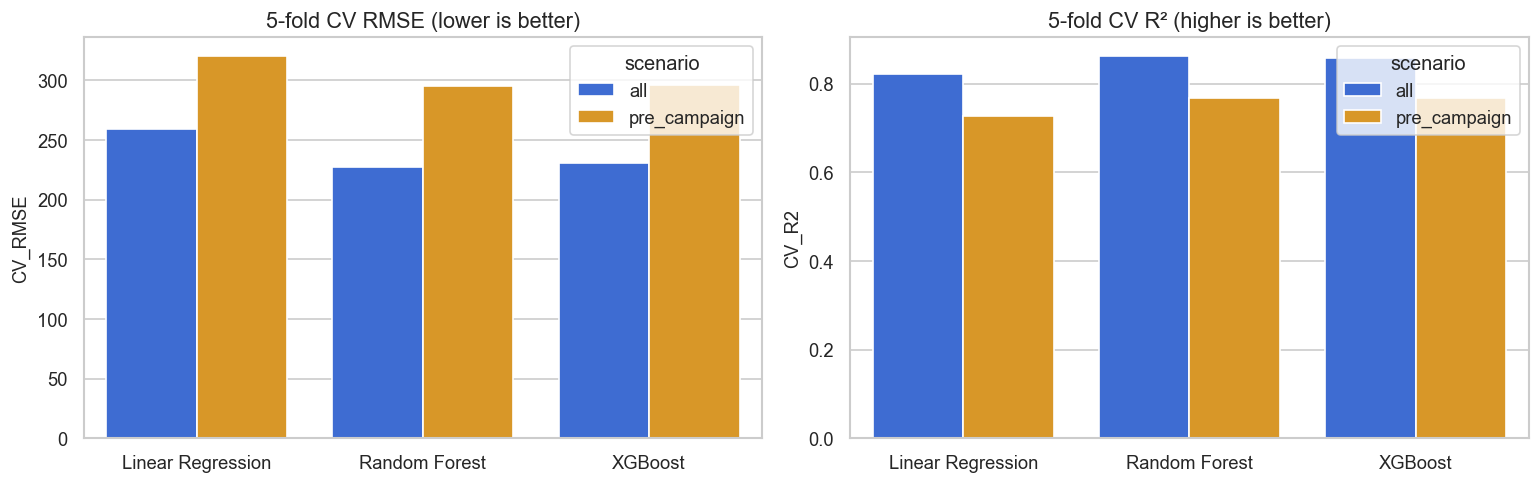

In [18]:
rows = [cv_eval(n, sc, best_target[n] == "log1p") for n in BASE_MODELS for sc in ("all", "pre_campaign")]
cv_scen = pd.DataFrame(rows)
display(cv_scen.round(3).sort_values(["scenario", "CV_RMSE"]).reset_index(drop=True))

plot_df = cv_scen[cv_scen.model != "Baseline (mean)"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.barplot(data=plot_df, x="model", y="CV_RMSE", hue="scenario", ax=axes[0], palette=["#2563eb", "#f59e0b"])
axes[0].set_title("5-fold CV RMSE (lower is better)"); axes[0].set_xlabel("")
sns.barplot(data=plot_df, x="model", y="CV_R2", hue="scenario", ax=axes[1], palette=["#2563eb", "#f59e0b"])
axes[1].set_title("5-fold CV R² (higher is better)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

## 8. Hyper-parameter tuning
`RandomizedSearchCV` (5-fold, optimizing RMSE) on the training set for Random Forest and XGBoost. Linear Regression has no hyper-parameters worth tuning and stays as the simple baseline.

In [19]:
FINAL_SCENARIO = "all"      # feature scenario used for the saved model

PARAM_GRIDS = {
    "Random Forest": {
        "n_estimators": [200, 300, 500],
        "max_depth": [None, 6, 10, 15],
        "min_samples_leaf": [1, 2, 4, 8],
        "max_features": ["sqrt", 0.5, 1.0],
    },
    "XGBoost": {
        "n_estimators": [200, 400, 600],
        "learning_rate": [0.02, 0.05, 0.1],
        "max_depth": [2, 3, 4, 6],
        "subsample": [0.7, 0.85, 1.0],
        "colsample_bytree": [0.7, 0.85, 1.0],
        "min_child_weight": [1, 3, 5],
        "reg_lambda": [1, 5, 10],
    },
}

searches = {}
for name, grid in PARAM_GRIDS.items():
    log_t = best_target[name] == "log1p"
    prefix = "model__regressor__" if log_t else "model__"
    pipe = make_pipeline(X_train, FINAL_SCENARIO, wrap_target(BASE_MODELS[name](), log_t))
    search = RandomizedSearchCV(pipe, {prefix + k: v for k, v in grid.items()}, n_iter=25, cv=KF,
                                scoring="neg_root_mean_squared_error", random_state=RANDOM_STATE,
                                n_jobs=N_JOBS, refit=True)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"{name:14s} target={best_target[name]:5s} best CV RMSE={-search.best_score_:8.2f}")
    print("   best params:", {k.replace(prefix, ""): v for k, v in search.best_params_.items()})

Random Forest  target=raw   best CV RMSE=  224.55
   best params: {'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 15}
XGBoost        target=raw   best CV RMSE=  222.78
   best params: {'subsample': 0.7, 'reg_lambda': 1, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.02, 'colsample_bytree': 0.85}


## 9. Final comparison and model selection
Each finalist is refit on the full training set and scored once on the untouched test set. The **best model is chosen by cross-validated RMSE** (so the test set stays an honest, final check).

In [20]:
finalists = {
    "Baseline (mean)":   make_pipeline(X_train, FINAL_SCENARIO, wrap_target(BASE_MODELS["Baseline (mean)"](), False)),
    "Linear Regression": make_pipeline(X_train, FINAL_SCENARIO, wrap_target(BASE_MODELS["Linear Regression"](), best_target["Linear Regression"] == "log1p")),
    "Random Forest":     searches["Random Forest"].best_estimator_,
    "XGBoost":           searches["XGBoost"].best_estimator_,
}

records = []
fitted = {}
for name, pipe in finalists.items():
    cv = cross_validate(clone(pipe), X_train, y_train, cv=KF, scoring=SCORING, n_jobs=N_JOBS)
    pipe = clone(pipe).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    records.append({
        "Model": name,
        "Target": "raw" if name == "Baseline (mean)" else best_target[name],
        "CV_MAE": -cv["test_MAE"].mean(), "CV_RMSE": -cv["test_RMSE"].mean(), "CV_R2": cv["test_R2"].mean(),
        "Test_MAE": mean_absolute_error(y_test, pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test_R2": r2_score(y_test, pred),
    })

metrics = pd.DataFrame(records).set_index("Model")
display(metrics.round(3))

candidates = metrics.drop(index="Baseline (mean)")
BEST_NAME = candidates["CV_RMSE"].idxmin()
best_pipeline = fitted[BEST_NAME]
print(f"\nSelected model: {BEST_NAME}  (lowest cross-validated RMSE among Linear Regression / Random Forest / XGBoost)")

,Target,CV_MAE,CV_RMSE,CV_R2,Test_MAE,Test_RMSE,Test_R2
Model,,,,,,,
Baseline (mean),raw,527.012,614.621,-0.003,477.448,553.403,-0.005
Linear Regression,raw,173.675,259.363,0.821,165.172,223.277,0.836
Random Forest,raw,124.359,224.548,0.865,103.955,175.901,0.898
XGBoost,raw,125.781,222.783,0.867,104.359,170.623,0.904



Selected model: XGBoost  (lowest cross-validated RMSE among Linear Regression / Random Forest / XGBoost)


## 10. Diagnostics of the selected model

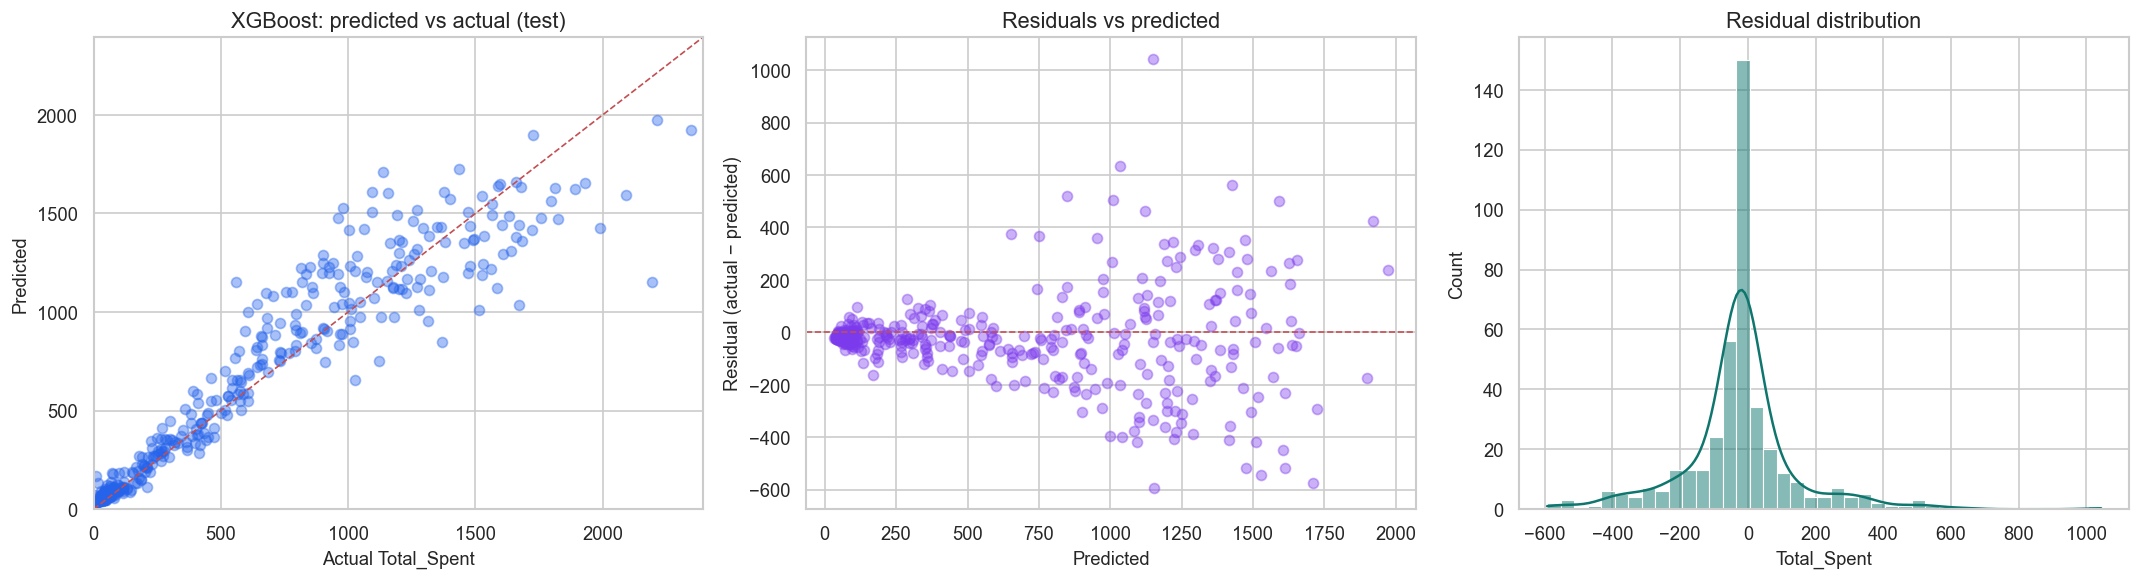

Share of test predictions within ±$100 of actual: 68.9%
Negative predictions: 0 of 412


In [21]:
pred_test = best_pipeline.predict(X_test)
resid = y_test - pred_test

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_test, pred_test, alpha=.4, color="#2563eb")
lim = [0, max(y_test.max(), pred_test.max()) * 1.02]
axes[0].plot(lim, lim, "r--", lw=1); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("Actual Total_Spent"); axes[0].set_ylabel("Predicted"); axes[0].set_title(f"{BEST_NAME}: predicted vs actual (test)")
axes[1].scatter(pred_test, resid, alpha=.4, color="#7c3aed"); axes[1].axhline(0, color="r", ls="--", lw=1)
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Residual (actual − predicted)"); axes[1].set_title("Residuals vs predicted")
sns.histplot(resid, kde=True, color="#0f766e", ax=axes[2]); axes[2].set_title("Residual distribution")
plt.tight_layout(); plt.show()

print(f"Share of test predictions within ±$100 of actual: {(resid.abs() <= 100).mean():.1%}")
print(f"Negative predictions: {(pred_test < 0).sum()} of {len(pred_test)}")

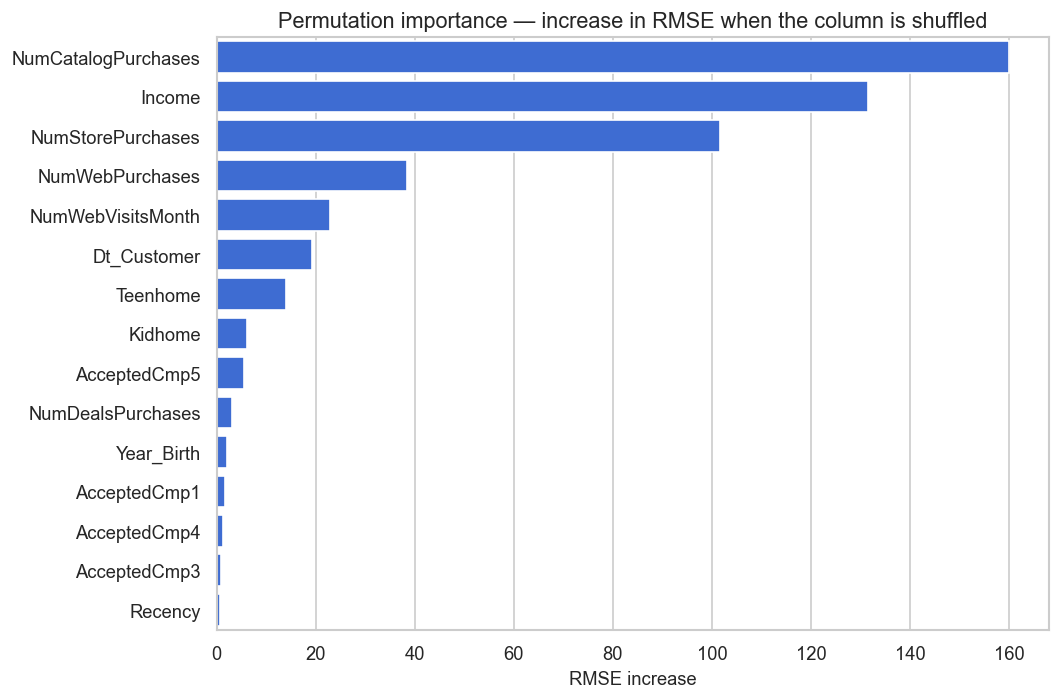

In [22]:
# Permutation importance on the RAW input columns (the pipeline does the feature engineering internally)
perm = permutation_importance(best_pipeline, X_test, y_test, n_repeats=15, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error", n_jobs=N_JOBS)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
plt.figure(figsize=(9, 6))
sns.barplot(x=imp.head(15).values, y=imp.head(15).index, color="#2563eb")
plt.title("Permutation importance — increase in RMSE when the column is shuffled"); plt.xlabel("RMSE increase"); plt.ylabel("")
plt.tight_layout(); plt.show()

## 11. Save the model and hand off to the application teams
Deliverables written next to the notebook:

| File | Purpose |
|---|---|
| `model/model_pipeline.pkl` | Preprocessing + best model in **one** pipeline — accepts raw customer columns |
| `preprocessing.py` | Custom transformers required to unpickle the pipeline |
| `model/feature_schema.json` | Input columns, types, allowed values, ranges, example request |
| `model/metrics.csv` | Metrics table of all compared models |

In [23]:
MODEL_DIR = Path("model"); MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(best_pipeline, MODEL_DIR / "model_pipeline.pkl")
metrics.round(4).to_csv(MODEL_DIR / "metrics.csv")

# ---- shared feature schema (all teams must use these exact names / types) ----
def column_spec(col):
    s = X_train[col]
    if col == "Dt_Customer":
        return {"type": "date", "format": "DD-MM-YYYY", "example": "04-09-2012"}
    if not pd.api.types.is_numeric_dtype(s):
        return {"type": "category", "allowed": sorted(s.dropna().unique().tolist())}
    binary = set(s.dropna().unique()) <= {0, 1}
    spec = {"type": "binary (0/1)" if binary else "number", "min": float(s.min()), "max": float(s.max())}
    if s.isna().any(): spec["nullable"] = True
    return spec

example_row = X_test.iloc[0].to_dict()
example_row = {k: (v.item() if hasattr(v, "item") else v) for k, v in example_row.items()}
example_row = {k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in example_row.items()}

schema = {
    "target": "Total_Spent",
    "task": "regression",
    "selected_model": BEST_NAME,
    "feature_scenario": FINAL_SCENARIO,
    "input_columns": {c: column_spec(c) for c in X_train.columns},
    "example_request": example_row,
    "leakage_note": "Never send MntWines/MntFruits/MntMeatProducts/MntFishProducts/MntSweetProducts/MntGoldProds, ID or Z_* columns.",
    "test_metrics": {k: round(float(v), 4) for k, v in metrics.loc[BEST_NAME, ["Test_MAE", "Test_RMSE", "Test_R2"]].items()},
    "environment": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
(MODEL_DIR / "feature_schema.json").write_text(json.dumps(schema, indent=2))
print("Saved:", [p.name for p in sorted(MODEL_DIR.iterdir())], "+ preprocessing.py")
print(json.dumps(schema["example_request"], indent=2))

Saved: ['feature_schema.json', 'metrics.csv', 'model_pipeline.pkl'] + preprocessing.py
{
  "Year_Birth": 1971,
  "Education": "Master",
  "Marital_Status": "Single",
  "Income": 33316.0,
  "Kidhome": 1,
  "Teenhome": 1,
  "Dt_Customer": "04-10-2013",
  "Recency": 34,
  "NumDealsPurchases": 3,
  "NumWebPurchases": 2,
  "NumCatalogPurchases": 1,
  "NumStorePurchases": 4,
  "NumWebVisitsMonth": 6,
  "AcceptedCmp3": 0,
  "AcceptedCmp4": 0,
  "AcceptedCmp5": 0,
  "AcceptedCmp1": 0,
  "AcceptedCmp2": 0,
  "Complain": 0,
  "Response": 0
}


### 11.1 Reload test — simulate what Gradio / FastAPI will do
Load the pickle in a **fresh Python process** (no notebook state, no retraining) and send raw customer data.

In [24]:
check = r'''
import joblib, json, pandas as pd
pipe = joblib.load("model/model_pipeline.pkl")
schema = json.load(open("model/feature_schema.json"))
row = pd.DataFrame([schema["example_request"]])[list(schema["input_columns"])]
print(round(float(pipe.predict(row)[0]), 2))
'''
out = subprocess.run([sys.executable, "-c", check], capture_output=True, text=True)
assert out.returncode == 0, out.stderr
fresh_prediction = float(out.stdout.strip().splitlines()[-1])
in_memory = float(best_pipeline.predict(X_test.iloc[[0]])[0])
print("Prediction in a fresh process :", fresh_prediction)
print("Prediction inside the notebook:", round(in_memory, 2))
assert abs(fresh_prediction - in_memory) < 0.01, "Saved pipeline does not reproduce the in-memory predictions"
print("OK — the saved pipeline reloads and reproduces the same prediction.")

Prediction in a fresh process : 109.65
Prediction inside the notebook: 109.65
OK — the saved pipeline reloads and reproduces the same prediction.


### 11.2 Example predictions and test cases
The same cases should be reused by the Gradio, FastAPI and Next.js stages (low / medium / high spender from the test set, plus hand-written inputs including edge cases).

In [25]:
loaded = joblib.load(MODEL_DIR / "model_pipeline.pkl")

# (a) real test customers: lowest, median and highest actual spender
order = y_test.sort_values().index
picks = [order[0], order[len(order) // 2], order[-1]]
cases = X_test.loc[picks].copy()
cases_out = cases[["Year_Birth", "Education", "Marital_Status", "Income", "Kidhome", "Teenhome", "NumWebPurchases", "NumStorePurchases"]].copy()
cases_out["Actual"] = y_test.loc[picks].values
cases_out["Predicted"] = loaded.predict(cases).round(1)
cases_out["Abs_Error"] = (cases_out["Actual"] - cases_out["Predicted"]).abs().round(1)
display(cases_out)

# (b) hand-written inputs, exactly like a web form / JSON request would send them
manual = pd.DataFrame([
    # typical mid-income family
    dict(Year_Birth=1980, Education="Graduation", Marital_Status="Married", Income=52000, Kidhome=1, Teenhome=0,
         Dt_Customer="15-06-2013", Recency=30, NumDealsPurchases=3, NumWebPurchases=4, NumCatalogPurchases=2,
         NumStorePurchases=6, NumWebVisitsMonth=5, AcceptedCmp3=0, AcceptedCmp4=0, AcceptedCmp5=0, AcceptedCmp1=0,
         AcceptedCmp2=0, Complain=0, Response=0),
    # high-income, no children, many purchases
    dict(Year_Birth=1965, Education="PhD", Marital_Status="Single", Income=95000, Kidhome=0, Teenhome=0,
         Dt_Customer="01-02-2013", Recency=10, NumDealsPurchases=1, NumWebPurchases=6, NumCatalogPurchases=8,
         NumStorePurchases=10, NumWebVisitsMonth=3, AcceptedCmp3=0, AcceptedCmp4=1, AcceptedCmp5=1, AcceptedCmp1=1,
         AcceptedCmp2=0, Complain=0, Response=1),
    # edge case: missing income and an unseen marital-status label
    dict(Year_Birth=1990, Education="Basic", Marital_Status="Widow", Income=None, Kidhome=2, Teenhome=1,
         Dt_Customer="20-11-2013", Recency=90, NumDealsPurchases=6, NumWebPurchases=2, NumCatalogPurchases=0,
         NumStorePurchases=3, NumWebVisitsMonth=8, AcceptedCmp3=0, AcceptedCmp4=0, AcceptedCmp5=0, AcceptedCmp1=0,
         AcceptedCmp2=0, Complain=1, Response=0),
])[list(X_train.columns)]
manual_pred = loaded.predict(manual)
display(pd.DataFrame({"case": ["mid-income family", "high-income, many purchases", "edge: missing income / odd label"],
                      "predicted_total_spent": manual_pred.round(1)}))

lo, hi = float(y.min()), float(y.max())
assert np.isfinite(manual_pred).all(), "Non-finite prediction"
assert ((manual_pred > lo - 100) & (manual_pred < hi + 500)).all(), "A prediction is outside a sensible range"
print(f"All test cases returned finite predictions in a reasonable range (training spend range {lo:.0f}–{hi:.0f}).")

,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,NumWebPurchases,NumStorePurchases,Actual,Predicted,Abs_Error
981,1965,Graduation,Divorced,4861.0,0,0,0,0,6,72.400002,66.4
542,1984,PhD,Single,42710.0,1,0,4,3,406,583.099976,177.1
1288,1972,Master,Married,83151.0,0,0,5,10,2346,1921.000000,425.0


,case,predicted_total_spent
0,mid-income family,326.299988
1,"high-income, many purchases",1738.000000
2,edge: missing income / odd label,98.800003


All test cases returned finite predictions in a reasonable range (training spend range 5–2525).


## 12. Conclusions

In [26]:
m = metrics.loc[BEST_NAME]
base = metrics.loc["Baseline (mean)"]
pre = cv_scen[(cv_scen.scenario == "pre_campaign") & (cv_scen.model == BEST_NAME)]
lines = [
    f"**Selected model:** {BEST_NAME} (target treatment: *{m['Target']}*, feature scenario: *{FINAL_SCENARIO}*).",
    f"**Test performance:** MAE = {m['Test_MAE']:.1f}, RMSE = {m['Test_RMSE']:.1f}, R² = {m['Test_R2']:.3f} "
    f"(mean-only baseline: MAE = {base['Test_MAE']:.1f}, RMSE = {base['Test_RMSE']:.1f}, R² = {base['Test_R2']:.3f}).",
    f"**Cross-validation (train):** RMSE = {m['CV_RMSE']:.1f}, R² = {m['CV_R2']:.3f} — consistent with the test result, so no sign of overfitting to the split.",
    f"**Most important raw inputs:** " + ", ".join(imp.head(5).index) + ".",
]
if len(pre):
    lines.append(f"**Without purchase / campaign information (`pre_campaign`)** the same model reaches CV R² = {pre['CV_R2'].iloc[0]:.3f} "
                 f"(RMSE {pre['CV_RMSE'].iloc[0]:.1f}); the web form needs the purchase fields to get the accuracy above.")
lines.append("**Handoff:** load `model/model_pipeline.pkl` with `joblib`, keep `preprocessing.py` importable, send the columns listed in `model/feature_schema.json`, and never retrain in the app.")
display(Markdown("\n\n".join("- " + l for l in lines)))

- **Selected model:** XGBoost (target treatment: *raw*, feature scenario: *all*).

- **Test performance:** MAE = 104.4, RMSE = 170.6, R² = 0.904 (mean-only baseline: MAE = 477.4, RMSE = 553.4, R² = -0.005).

- **Cross-validation (train):** RMSE = 222.8, R² = 0.867 — consistent with the test result, so no sign of overfitting to the split.

- **Most important raw inputs:** NumCatalogPurchases, Income, NumStorePurchases, NumWebPurchases, NumWebVisitsMonth.

- **Without purchase / campaign information (`pre_campaign`)** the same model reaches CV R² = 0.768 (RMSE 295.7); the web form needs the purchase fields to get the accuracy above.

- **Handoff:** load `model/model_pipeline.pkl` with `joblib`, keep `preprocessing.py` importable, send the columns listed in `model/feature_schema.json`, and never retrain in the app.